
# Fase 3 — Análisis de Datos

## Notebook 01: Diagnóstico de calidad

**Proyecto:** Pokémon Team Recommender

### Objetivo

Evaluar la calidad de los datos procesados durante Ingeniería de Datos mediante el análisis de dimensiones, tipos de datos, valores faltantes, duplicados y distribuciones.

### Alcance

- 151 Pokémon.
- 151 especies.
- 18 tipos principales.
- 9 tablas procesadas.
- 324 relaciones de efectividad.
- 2,718 perfiles defensivos.

Este notebook realiza únicamente análisis y diagnóstico. No modifica los datos originales ni aplica tratamientos de limpieza.


In [24]:

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

def find_project_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (
            (path / "ingenieria").is_dir()
            and (path / "data" / "processed").is_dir()
        ):
            return path

    raise FileNotFoundError(
        "No se encontró la raíz del proyecto."
    )

ROOT = find_project_root(Path.cwd())
PROCESSED = ROOT / "data" / "processed"

print("Raíz:", ROOT)
print("Datos procesados:", PROCESSED)


Raíz: c:\Users\REYES\OneDrive\Desktop\pokemon team recommended
Datos procesados: c:\Users\REYES\OneDrive\Desktop\pokemon team recommended\data\processed


In [25]:

table_names = [
    "pokemon",
    "pokemon_stats",
    "pokemon_types",
    "pokemon_abilities",
    "species",
    "pokemon_varieties",
    "types",
    "type_effectiveness",
    "pokemon_defensive_profile",
]

tables = {}

for name in table_names:
    path = PROCESSED / f"{name}.csv"

    if not path.exists():
        raise FileNotFoundError(
            f"No existe el archivo: {path}"
        )

    tables[name] = pd.read_csv(path)

    print(
        f"[OK] {name}: "
        f"{tables[name].shape[0]} filas, "
        f"{tables[name].shape[1]} columnas"
    )



[OK] pokemon: 151 filas, 7 columnas
[OK] pokemon_stats: 906 filas, 3 columnas
[OK] pokemon_types: 218 filas, 4 columnas
[OK] pokemon_abilities: 395 filas, 5 columnas
[OK] species: 151 filas, 7 columnas
[OK] pokemon_varieties: 238 filas, 4 columnas
[OK] types: 18 filas, 2 columnas
[OK] type_effectiveness: 324 filas, 6 columnas
[OK] pokemon_defensive_profile: 2718 filas, 6 columnas


In [26]:

structure = []

for name, df in tables.items():
    structure.append({
        "tabla": name,
        "filas": len(df),
        "columnas": len(df.columns),
        "nulos": int(df.isna().sum().sum()),
        "duplicados_exactos": int(
            df.duplicated().sum()
        ),
        "memoria_mb": round(
            df.memory_usage(deep=True).sum()
            / (1024 ** 2),
            4,
        ),
    })

df_structure = pd.DataFrame(structure)

display(df_structure)


,tabla,filas,columnas,nulos,duplicados_exactos,memoria_mb
0,pokemon,151,7,0,0,0.0141
1,pokemon_stats,906,3,0,0,0.0633
2,pokemon_types,218,4,0,0,0.0164
3,pokemon_abilities,395,5,0,0,0.0315
4,species,151,7,0,0,0.0277
5,pokemon_varieties,238,4,0,0,0.0173
6,types,18,2,0,0,0.0012
7,type_effectiveness,324,6,0,0,0.0609
8,pokemon_defensive_profile,2718,6,0,0,0.5150


In [27]:

# Diagnóstico de valores faltantes

missing_records = []

for name, df in tables.items():
    for column in df.columns:
        missing = int(df[column].isna().sum())

        if missing > 0:
            missing_records.append({
                "tabla": name,
                "columna": column,
                "nulos": missing,
                "porcentaje": round(
                    missing / len(df) * 100, 2
                ),
            })

df_missing = pd.DataFrame(
    missing_records,
    columns=["tabla", "columna", "nulos", "porcentaje"]
)

if df_missing.empty:
    print("No se detectaron valores nulos.")
else:
    display(
        df_missing.sort_values(
            "porcentaje",
            ascending=False
        )
    )


No se detectaron valores nulos.


In [28]:
print("Variable creada:", isinstance(df_missing, pd.DataFrame))
print("Registros con nulos:", len(df_missing))

Variable creada: True
Registros con nulos: 0


In [29]:

duplicate_summary = pd.DataFrame([
    {
        "tabla": name,
        "duplicados_exactos": int(
            df.duplicated().sum()
        ),
    }
    for name, df in tables.items()
])

display(duplicate_summary)


,tabla,duplicados_exactos
0,pokemon,0
1,pokemon_stats,0
2,pokemon_types,0
3,pokemon_abilities,0
4,species,0
5,pokemon_varieties,0
6,types,0
7,type_effectiveness,0
8,pokemon_defensive_profile,0


In [30]:

pokemon = tables["pokemon"]
stats = tables["pokemon_stats"]

print("=== ATRIBUTOS NUMÉRICOS DE POKÉMON ===")
display(
    pokemon[
        ["height_dm", "weight_hg", "base_experience"]
    ].describe()
)

print("=== ESTADÍSTICAS BASE ===")
display(
    stats.groupby("stat_name")["base_stat"]
    .describe()
)


=== ATRIBUTOS NUMÉRICOS DE POKÉMON ===


,height_dm,weight_hg,base_experience
count,151.000000,151.000000,151.000000
mean,11.947020,459.516556,135.052980
std,9.626206,594.479883,67.719794
min,2.000000,1.000000,39.000000
25%,7.000000,99.000000,65.000000
50%,10.000000,300.000000,142.000000
75%,15.000000,562.500000,176.000000
max,88.000000,4600.000000,395.000000


=== ESTADÍSTICAS BASE ===


,count,mean,std,min,25%,50%,75%,max
stat_name,,,,,,,,
attack,151.0,72.913907,26.755421,5.0,51.0,70.0,92.0,134.0
defense,151.0,68.225166,26.916704,5.0,50.0,65.0,84.0,180.0
hp,151.0,64.211921,28.590117,10.0,45.0,60.0,80.0,250.0
special-attack,151.0,67.139073,28.534199,15.0,45.0,65.0,87.5,154.0
special-defense,151.0,66.086093,24.208797,20.0,49.0,65.0,80.0,125.0
speed,151.0,69.066225,27.024598,15.0,46.5,70.0,90.0,150.0


In [31]:

outlier_records = []

for stat_name, group in stats.groupby("stat_name"):
    values = group["base_stat"]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = group[
        (values < lower) | (values > upper)
    ]

    outlier_records.append({
        "estadistica": stat_name,
        "limite_inferior": lower,
        "limite_superior": upper,
        "atipicos": len(outliers),
        "porcentaje": round(
            len(outliers) / len(group) * 100, 2
        ),
    })

df_outliers = pd.DataFrame(outlier_records)

display(df_outliers)


,estadistica,limite_inferior,limite_superior,atipicos,porcentaje
0,attack,-10.50,153.50,0,0.00
1,defense,-1.00,135.00,2,1.32
2,hp,-7.50,132.50,3,1.99
3,special-attack,-18.75,151.25,1,0.66
4,special-defense,2.50,126.50,0,0.00
5,speed,-18.75,155.25,0,0.00


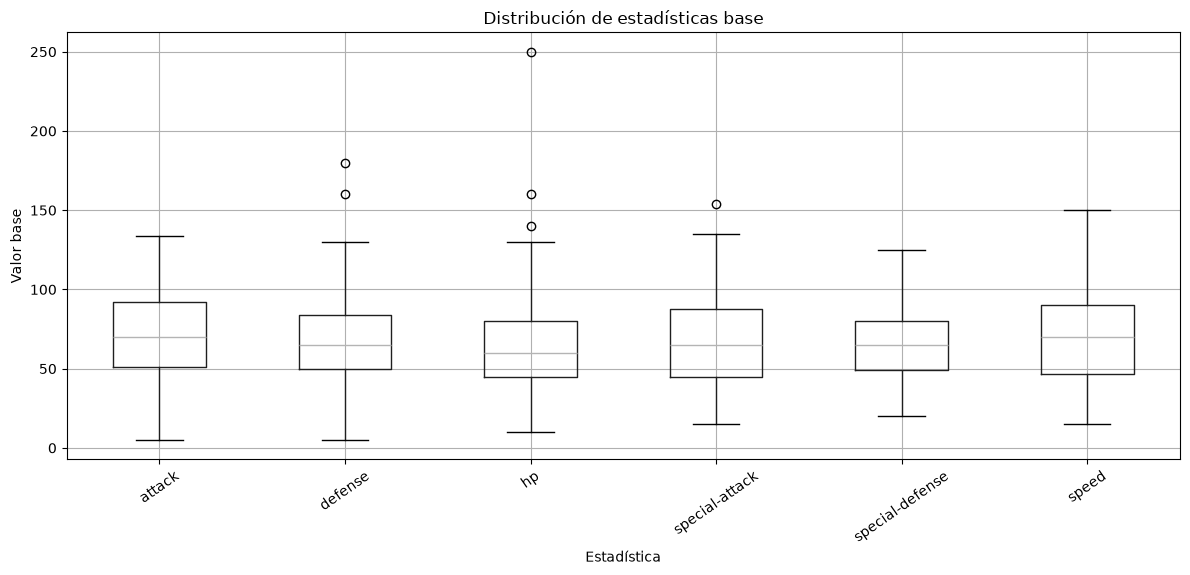

In [32]:

stats.boxplot(
    column="base_stat",
    by="stat_name",
    figsize=(12, 6),
    rot=35,
)

plt.title("Distribución de estadísticas base")
plt.suptitle("")
plt.xlabel("Estadística")
plt.ylabel("Valor base")
plt.tight_layout()
plt.show()


In [33]:

RESULTS = ROOT / "analisis" / "resultados"
RESULTS.mkdir(parents=True, exist_ok=True)

df_structure.to_csv(
    RESULTS / "diagnostico_estructura.csv",
    index=False,
)

df_missing.to_csv(
    RESULTS / "diagnostico_nulos.csv",
    index=False,
)

duplicate_summary.to_csv(
    RESULTS / "diagnostico_duplicados.csv",
    index=False,
)

df_outliers.to_csv(
    RESULTS / "diagnostico_atipicos.csv",
    index=False,
)

print("Diagnóstico exportado correctamente.")


Diagnóstico exportado correctamente.


In [34]:

print("=== ESTRUCTURA ===")
display(df_structure)

print("\n=== VALORES FALTANTES ===")
display(df_missing)

print("\n=== DUPLICADOS ===")
display(duplicate_summary)

print("\n=== VALORES ATÍPICOS ===")
display(df_outliers)


=== ESTRUCTURA ===


,tabla,filas,columnas,nulos,duplicados_exactos,memoria_mb
0,pokemon,151,7,0,0,0.0141
1,pokemon_stats,906,3,0,0,0.0633
2,pokemon_types,218,4,0,0,0.0164
3,pokemon_abilities,395,5,0,0,0.0315
4,species,151,7,0,0,0.0277
5,pokemon_varieties,238,4,0,0,0.0173
6,types,18,2,0,0,0.0012
7,type_effectiveness,324,6,0,0,0.0609
8,pokemon_defensive_profile,2718,6,0,0,0.5150



=== VALORES FALTANTES ===


,tabla,columna,nulos,porcentaje



=== DUPLICADOS ===


,tabla,duplicados_exactos
0,pokemon,0
1,pokemon_stats,0
2,pokemon_types,0
3,pokemon_abilities,0
4,species,0
5,pokemon_varieties,0
6,types,0
7,type_effectiveness,0
8,pokemon_defensive_profile,0



=== VALORES ATÍPICOS ===


,estadistica,limite_inferior,limite_superior,atipicos,porcentaje
0,attack,-10.50,153.50,0,0.00
1,defense,-1.00,135.00,2,1.32
2,hp,-7.50,132.50,3,1.99
3,special-attack,-18.75,151.25,1,0.66
4,special-defense,2.50,126.50,0,0.00
5,speed,-18.75,155.25,0,0.00


In [35]:

# Identificar Pokémon con estadísticas atípicas

pokemon = tables["pokemon"]
stats = tables["pokemon_stats"]

outlier_details = []

for stat_name, group in stats.groupby("stat_name"):
    q1 = group["base_stat"].quantile(0.25)
    q3 = group["base_stat"].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    detected = group[
        (group["base_stat"] < lower) |
        (group["base_stat"] > upper)
    ].copy()

    detected["limite_inferior"] = lower
    detected["limite_superior"] = upper

    outlier_details.append(detected)

df_outlier_details = pd.concat(
    outlier_details,
    ignore_index=True
)

# Verificar nombres de columnas disponibles
print("Columnas de pokemon:", pokemon.columns.tolist())
print("Columnas de stats:", stats.columns.tolist())

display(df_outlier_details)


Columnas de pokemon: ['pokemon_id', 'pokemon_name', 'species_id', 'is_default', 'height_dm', 'weight_hg', 'base_experience']
Columnas de stats: ['pokemon_id', 'stat_name', 'base_stat']


,pokemon_id,stat_name,base_stat,limite_inferior,limite_superior
0,91,defense,180,-1.00,135.00
1,95,defense,160,-1.00,135.00
2,40,hp,140,-7.50,132.50
3,113,hp,250,-7.50,132.50
4,143,hp,160,-7.50,132.50
5,150,special-attack,154,-18.75,151.25


In [36]:

# Relacionar estadísticas atípicas con nombres de Pokémon

df_atipicos_pokemon = df_outlier_details.merge(
    pokemon[["pokemon_id", "pokemon_name"]],
    on="pokemon_id",
    how="left",
    validate="many_to_one"
)

df_atipicos_pokemon = df_atipicos_pokemon[
    [
        "pokemon_id",
        "pokemon_name",
        "stat_name",
        "base_stat",
        "limite_inferior",
        "limite_superior"
    ]
].sort_values(
    by=["stat_name", "base_stat"],
    ascending=[True, False]
)

print("=== POKÉMON CON ESTADÍSTICAS ATÍPICAS ===")
display(df_atipicos_pokemon)

print(
    "Total de registros atípicos:",
    len(df_atipicos_pokemon)
)


=== POKÉMON CON ESTADÍSTICAS ATÍPICAS ===


,pokemon_id,pokemon_name,stat_name,base_stat,limite_inferior,limite_superior
0,91,cloyster,defense,180,-1.00,135.00
1,95,onix,defense,160,-1.00,135.00
3,113,chansey,hp,250,-7.50,132.50
4,143,snorlax,hp,160,-7.50,132.50
2,40,wigglytuff,hp,140,-7.50,132.50
5,150,mewtwo,special-attack,154,-18.75,151.25


Total de registros atípicos: 6


In [37]:

# Validación inicial de integridad

pokemon = tables["pokemon"]
stats = tables["pokemon_stats"]
pokemon_types = tables["pokemon_types"]
species = tables["species"]

checks = {
    "pokemon_id único": pokemon["pokemon_id"].is_unique,

    "151 Pokémon": len(pokemon) == 151,

    "6 estadísticas por Pokémon": (
        stats.groupby("pokemon_id")["stat_name"].nunique()
        .reindex(pokemon["pokemon_id"], fill_value=0)
        .eq(6).all()
    ),

    "Estadísticas no negativas": (
        stats["base_stat"] >= 0
    ).all(),

    "Species referenciadas existentes": (
        pokemon["species_id"].isin(
            species["species_id"]
        )
    ).all(),

    "Tipos referencian Pokémon existentes": (
        pokemon_types["pokemon_id"].isin(
            pokemon["pokemon_id"]
        )
    ).all(),
}

for check, passed in checks.items():
    status = "PASS" if passed else "FAIL"
    print(f"[{status}] {check}")

print(
    f"\nResultado: {sum(checks.values())}"
    f"/{len(checks)} verificaciones PASS"
)


[PASS] pokemon_id único
[PASS] 151 Pokémon
[PASS] 6 estadísticas por Pokémon
[PASS] Estadísticas no negativas
[PASS] Species referenciadas existentes
[PASS] Tipos referencian Pokémon existentes

Resultado: 6/6 verificaciones PASS


In [38]:

# Validaciones complementarias de dominio e integridad

pokemon = tables["pokemon"]
stats = tables["pokemon_stats"]
pokemon_types = tables["pokemon_types"]
types = tables["types"]
effectiveness = tables["type_effectiveness"]
defensive = tables["pokemon_defensive_profile"]

checks_extra = {
    "IDs positivos": pokemon["pokemon_id"].gt(0).all(),

    "Altura positiva": pokemon["height_dm"].gt(0).all(),

    "Peso positivo": pokemon["weight_hg"].gt(0).all(),

    "Estadísticas únicas por Pokémon": not stats.duplicated(
        subset=["pokemon_id", "stat_name"]
    ).any(),

    "Tipos sin duplicados por Pokémon": not pokemon_types.duplicated(
        subset=["pokemon_id", "type_id"]
    ).any(),

    "Tipos del catálogo únicos": types["type_id"].is_unique,

    "Multiplicadores permitidos": effectiveness[
        "multiplier"
    ].isin([0, 0.5, 1, 2]).all(),

    "324 relaciones de tipos": len(effectiveness) == 324,

    "2718 perfiles defensivos": len(defensive) == 2718,
}

for name, passed in checks_extra.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

print(
    f"\nResultado: {sum(checks_extra.values())}"
    f"/{len(checks_extra)} verificaciones PASS"
)


[PASS] IDs positivos
[PASS] Altura positiva
[PASS] Peso positivo
[PASS] Estadísticas únicas por Pokémon
[PASS] Tipos sin duplicados por Pokémon
[PASS] Tipos del catálogo únicos
[PASS] Multiplicadores permitidos
[PASS] 324 relaciones de tipos
[PASS] 2718 perfiles defensivos

Resultado: 9/9 verificaciones PASS
